In [2]:
import torch
import src.config as config
import numpy as np
from src.utils import get_train_stats, seed_worker
from src.dataset import PrecomputedDataset, mashup_collate_fn
from torch.utils.data import DataLoader
from src.models import ResNet, EffNetB0, ScratchCNN
from pathlib import Path
import src.config as config
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
import matplotlib.pyplot as plt
from tqdm import tqdm

Load in the model checkpoints.

In [2]:
effnet_finetuned = EffNetB0(num_classes=10, pretrained=False, freeze_backbone=True)
ckpt = torch.load(Path(config.CHECKPOINTS_DIR) / "effnetb0.ckpt", map_location="cpu", weights_only=False)
effnet_finetuned.load_state_dict(ckpt["model_state"])

resnet_finetuned = ResNet(num_classes=10, freeze_backbone=False)
ckpt = torch.load(Path(config.CHECKPOINTS_DIR) / "resnet.ckpt", map_location="cpu", weights_only=False)
resnet_finetuned.load_state_dict(ckpt["model_state"])

scratch_finetuned = ScratchCNN(num_classes=10)
ckpt = torch.load(Path(config.CHECKPOINTS_DIR) / "scratchcnn.ckpt", map_location="cpu", weights_only=False)
scratch_finetuned.load_state_dict(ckpt["model_state"])

<All keys matched successfully>

I'll just tweak my existing functions (`validate_loop` and `ensemble_predictions`) slightly.

In [3]:
def get_preds(model: torch.nn.Module, loader: DataLoader, device):
    model.to(device)
    model.eval()
    preds, targets = [], []

    with torch.inference_mode():
        for batch in tqdm(loader, leave=False):
            x = batch["mel"].to(device)
            y = batch["label"].to(device)
            logits = model(x)
            y_pred = logits.argmax(dim=1).detach().cpu().numpy()
            preds.append(y_pred)
            targets.append(y.detach().cpu().numpy())
    
    preds = np.concat(preds, axis=0)
    targets = np.concat(targets, axis=0)
    return preds, targets

def get_preds_ensemble(models, loader: DataLoader, device=None, batch_size=config.BATCH_SIZE, num_workers=0, weights=None):
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
    device = torch.device(device)

    models = list(models)
    n_models = len(models)

    # Model ensemble weights
    if weights is None:
        weights = np.ones(n_models, dtype=float)
    weights = np.array(weights, dtype=float)
    weights = weights / (weights.sum() + config.EPS)

    for m in models:
        m.to(device)
        m.eval()

    preds, targets = [], []

    with torch.inference_mode():
        for batch in tqdm(loader, leave=False):
            x = batch["mel"].to(device)
            y = batch["label"].to(device)
            agg = None
            for w, m in zip(weights, models):
                logits = m(x)
                logits_cpu = logits.detach().cpu().numpy()
                if agg is None:
                    agg = w * logits_cpu
                else:
                    agg += w * logits_cpu
            exp = np.exp(agg - np.max(agg, axis=1, keepdims=True))
            probs_batch = exp / (exp.sum(axis=1, keepdims=True) + config.EPS)
            # y_pred = probs_batch.argmax().detach().cpu().numpy()
            preds.append(probs_batch)
            targets.append(y.detach().cpu().numpy())
    
    preds = np.concat(preds, axis=0)
    targets = np.concat(targets, axis=0)
    return preds, targets

Load in the validation set.

In [ ]:
mean, std = get_train_stats(config.TRAIN_STATS_PATH)
val_set = PrecomputedDataset("precomputed/val_v4_list.txt", mean, std)
val_dataloader = DataLoader(
        dataset=val_set,
        batch_size=16,
        shuffle=False,
        num_workers=8,
        pin_memory=True,
        collate_fn=mashup_collate_fn,
        worker_init_fn=seed_worker,
    )

Confusion matrices and classification reports:

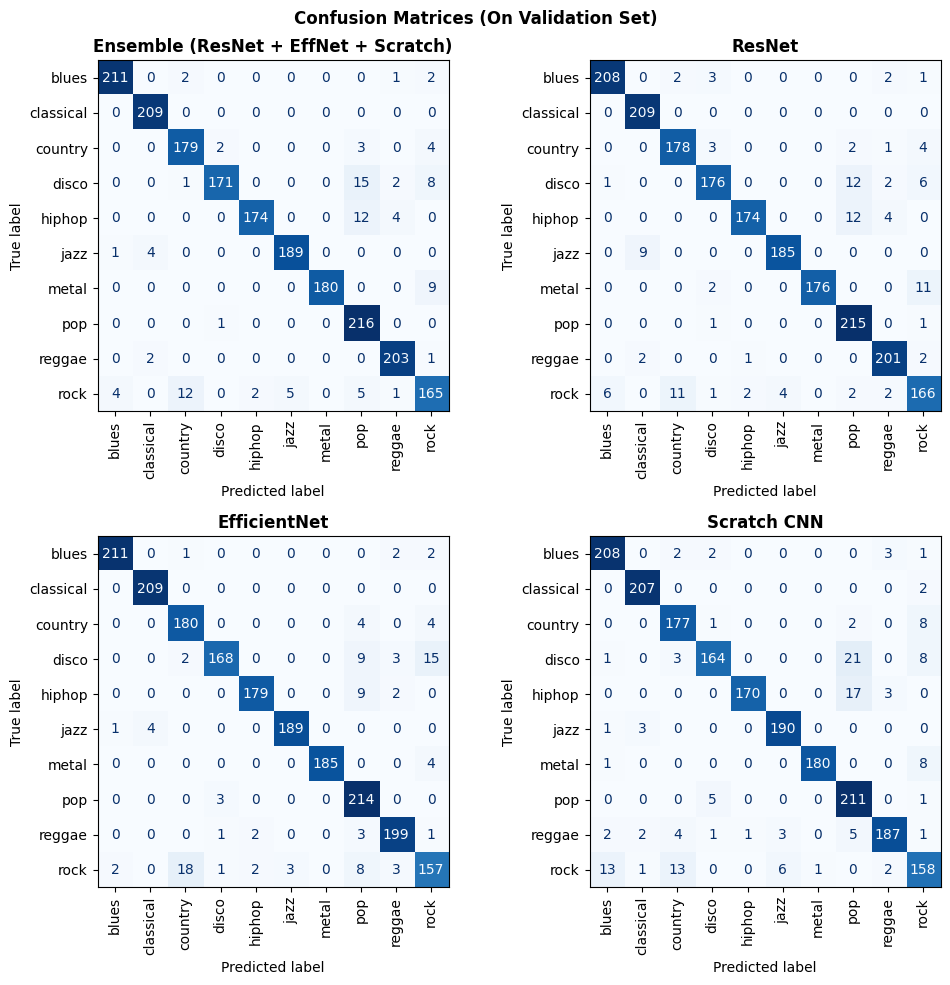

In [ ]:
ensemble_logits, targets = get_preds_ensemble([resnet_finetuned, effnet_finetuned, scratch_finetuned], val_dataloader)
ensemble_preds = [np.argmax(p) for p in ensemble_logits]
resnet_preds, _ = get_preds(resnet_finetuned, val_dataloader, "cuda")
effnet_preds, _ = get_preds(effnet_finetuned, val_dataloader, "cuda")
scratch_preds, _ = get_preds(scratch_finetuned, val_dataloader, "cuda")

fig, ax = plt.subplots(2, 2, figsize=(10,10))
ConfusionMatrixDisplay.from_predictions(targets, ensemble_preds, display_labels=config.GENRES, xticks_rotation="vertical", ax=ax[0][0], colorbar=False, cmap="Blues")
ConfusionMatrixDisplay.from_predictions(targets, resnet_preds, display_labels=config.GENRES, xticks_rotation="vertical", ax=ax[0][1], colorbar=False, cmap="Blues")
ConfusionMatrixDisplay.from_predictions(targets, effnet_preds, display_labels=config.GENRES, xticks_rotation="vertical", ax=ax[1][0], colorbar=False, cmap="Blues")
ConfusionMatrixDisplay.from_predictions(targets, scratch_preds, display_labels=config.GENRES, xticks_rotation="vertical", ax=ax[1][1], colorbar=False, cmap="Blues")
ax[0][0].set_title("Ensemble (ResNet + EffNet + Scratch)", fontweight="bold")
ax[0][1].set_title("ResNet", fontweight="bold")
ax[1][0].set_title("EfficientNet", fontweight="bold")
ax[1][1].set_title("Scratch CNN", fontweight="bold")
plt.suptitle("Confusion Matrices (On Validation Set)", fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
print("Macro F1:\n---")
print("ENSEMBLE:", round(f1_score(targets, ensemble_preds, average="macro"), 4))
print("RESNET:", round(f1_score(targets, resnet_preds, average="macro"), 4))
print("EFFNET:", round(f1_score(targets, effnet_preds, average="macro"), 4))
print("SCRATCH:", round(f1_score(targets, scratch_preds, average="macro"), 4))

Macro F1:
---
ENSEMBLE: 0.9481
RESNET: 0.9435
EFFNET: 0.9448
SCRATCH: 0.9259


In [54]:
print("ENSEMBLE:\n", classification_report(targets, ensemble_preds, digits=2, target_names=config.GENRES), "\n")
print("RESNET:\n", classification_report(targets, resnet_preds, digits=2, target_names=config.GENRES), "\n")
print("EFFICIENTNET:\n", classification_report(targets, effnet_preds, digits=2, target_names=config.GENRES), "\n")
print("SCRATCHCNN:\n", classification_report(targets, scratch_preds, digits=2, target_names=config.GENRES))

ENSEMBLE:
               precision    recall  f1-score   support

       blues       0.98      0.98      0.98       216
   classical       0.97      1.00      0.99       209
     country       0.92      0.95      0.94       188
       disco       0.98      0.87      0.92       197
      hiphop       0.99      0.92      0.95       190
        jazz       0.97      0.97      0.97       194
       metal       1.00      0.95      0.98       189
         pop       0.86      1.00      0.92       217
      reggae       0.96      0.99      0.97       206
        rock       0.87      0.85      0.86       194

    accuracy                           0.95      2000
   macro avg       0.95      0.95      0.95      2000
weighted avg       0.95      0.95      0.95      2000
 

RESNET:
               precision    recall  f1-score   support

       blues       0.97      0.96      0.97       216
   classical       0.95      1.00      0.97       209
     country       0.93      0.95      0.94       188
  

- The ensemble performed better than any individual model, while ScratchCNN did the worst.
- The ensemble had the highest TP count for pop and reggae, and performance on the other genres was either equal or only slightly lower.
- Rock was consistently misclassified as country by the models, and disco and hiphop as pop.
- Rock and pop were consistently the most misclassified genres.

### Miscellaneous
Visualizing attention weights from the ScratchCNNAttention I tried out.

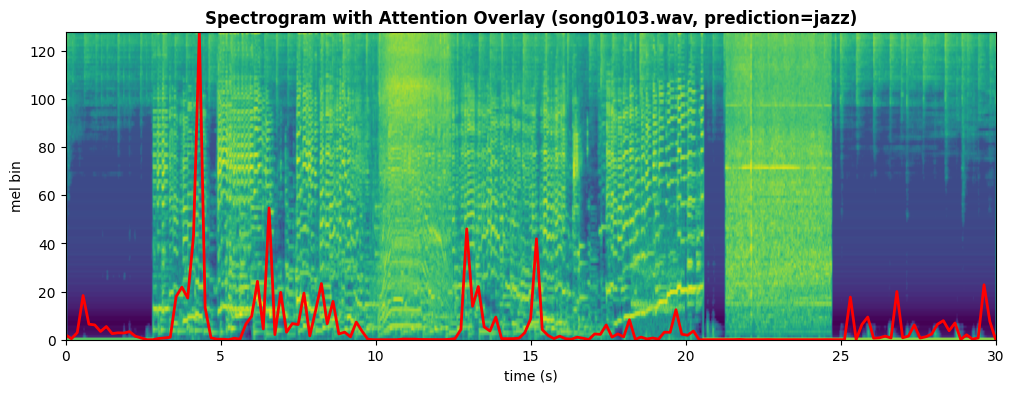

'jazz'

In [5]:
from src.audio import log_mel, pad_or_trim, load_audio
from src.models import ScratchCNNAttention

def visualize_attention(model, mel, name, sr=config.SR, hop_length=config.HOP_LENGTH, device="cpu"):
    """
    mel: tensor (1, 1, n_mels, T)
    """
    model.eval()
    mel = mel.to(device)

    with torch.inference_mode():
        logits, attn_weights = model(mel, return_attention=True)
    pred = config.idx_to_genre[np.argmax(logits.detach().cpu().numpy())]    
    # Move to CPU
    mel_np = mel.squeeze(0).squeeze(0).cpu().numpy() # (n_mels, T)
    attn_np = attn_weights.squeeze(0).cpu().numpy() # (T,)

    T_mel = mel_np.shape[1] # original spectrogram time bins
    T_attn = attn_np.shape[0] # attention time bins

    total_duration = T_mel * hop_length / sr
    time_axis_attn = np.linspace(0, total_duration, T_attn)
    time_axis_mel = np.linspace(0, total_duration, T_mel)
    attn_norm = (attn_np - attn_np.min()) / (attn_np.max() - attn_np.min() + config.EPS)

    plt.figure(figsize=(12, 4))
    plt.imshow(
        mel_np,
        aspect="auto",
        origin="lower",
        extent=[time_axis_mel[0], time_axis_mel[-1], 0, mel_np.shape[0]]
    )
    plt.plot(time_axis_attn, attn_norm * mel_np.shape[0], linewidth=2, color="red")
    plt.xlabel("time (s)")
    plt.ylabel("mel bin")
    plt.title(f"Spectrogram with Attention Overlay ({name}, prediction={pred})", fontweight="bold")
    plt.show()

    return pred

attn = ScratchCNNAttention(num_classes=10)
ckpt = torch.load("precomputed/scratch_attention_2.ckpt", map_location="cpu", weights_only=False)
attn.load_state_dict(ckpt["model_state"])
mean, std = get_train_stats(config.TRAIN_STATS_PATH)

mel = log_mel(pad_or_trim(load_audio(f"data/messy_mashup/mashups/song0103.wav", sr=config.SR)))
mel_t = torch.from_numpy(mel).unsqueeze(0).float()
mel_t = mel_t.unsqueeze(0)
mel_t = (mel_t - torch.tensor(mean, dtype=torch.float32).view(1, -1, 1)) / torch.tensor(std, dtype=torch.float32).view(1, -1, 1)
visualize_attention(attn, mel_t, "song0103.wav")